# SMIFC Portfolio Growth Trajectory
## Lewis University Student Managed Investment Fund Club

---

This notebook produces a **publication-quality infographic-style chart** showing the portfolio's
long-term growth from a **$5,000 university endowment** (1960s) to **$468,203** (December 2025),
styled to match the reference poster infographic.

### Visual Style
- Crimson red line with filled area underneath
- Large milestone markers with bold dollar-value labels
- Vertical dashed guidelines at key events
- Bottom timeline with date headers and narrative descriptions
- Clean white background, minimal grid

### Data Sources
| Period | Source | Status |
|--------|--------|--------|
| 1960s–2020 | Estimated compound growth (~7%/yr on $5,000 endowment) | Estimated |
| Oct 2021 | Update of Activities report ($351,399) | Verified |
| Aug 2022 | Fall 2022 semester report ($321,507) | Verified |
| Jun 2023 | June 2023 report ($332,066) | Verified |
| Dec 2023 | Dec 2023 report ($354,075) | Verified |
| Dec 2024 | Month End Market Values ($410,261) | Verified |
| Jan–Dec 2025 | Month End Market Values PDF (monthly) | Verified |
| Dec 2025 | Year-end statement ($468,203) | Verified |

---
## Section 1: Imports & Style Configuration

We use **matplotlib** for static high-resolution output suitable for poster printing.
The color palette is built around a **crimson red** (`#C0392B`) as the hero color,
matching the reference infographic.

**PCHIP interpolation** (Piecewise Cubic Hermite Interpolating Polynomial) is used
instead of standard cubic splines because it preserves monotonicity between data
points — preventing unrealistic oscillations in the historical growth curve.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
import os

# ============================================================
# STYLE CONFIGURATION  (matching reference infographic)
# ============================================================
RED          = '#C0392B'   # crimson for line & markers
RED_FILL     = '#C0392B'   # same, applied with low alpha
BLACK        = '#1A1A1A'
DARK_GRAY    = '#444444'
MED_GRAY     = '#777777'
LIGHT_GRAY   = '#CCCCCC'
VLIGHT_GRAY  = '#EEEEEE'

FIGURE_SIZE  = (13, 7.5)
EXPORT_DPI   = 300
LINE_WIDTH   = 3.2
MARKER_SIZE  = 11

plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Segoe UI', 'DejaVu Sans', 'Arial', 'Helvetica'],
    'axes.linewidth':    0.5,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'figure.dpi':        100,
})

print('Style configuration loaded.')

Style configuration loaded.


---
## Section 2: Data Points & Interpolation

### Non-Linear X-Axis
The chart uses **custom x-positions** rather than calendar dates to match the
reference layout:
- Positions **0–5**: Compress the 60-year history (1960s–2020) into ~35% of the chart width
- Positions **5–13**: Expand the recent period (2021–2025) into ~65% of the chart width

This gives the recent performance detail much more visual space, matching how
the reference infographic was designed.

### Historical Estimates
Pre-2021 values are estimated using ~7% compound annual growth on the original
$5,000 endowment. This produces a smooth exponential curve that is visually
consistent with the reference and financially reasonable for a balanced portfolio.

### Interpolation Method
PCHIP (Piecewise Cubic Hermite) produces a smooth curve that:
- Never overshoots between data points
- Preserves the shape of the bull rally rise and market correction dip
- Creates 800 interpolation points for a smooth visual

In [2]:
# ============================================================
# DATA POINTS
# ============================================================
# (custom_position, portfolio_value)
#
# Historical estimates use ~7%/yr compound growth on $5,000.
# All post-2021 values are verified from club documents.

curve_data = [
    # -- Historical (estimated) --
    # pos    value
    ( 0.0,     5000),    # 1962  – Original endowment
    ( 0.6,     9000),    # ~1970
    ( 1.2,    18000),    # ~1980
    ( 1.8,    36000),    # ~1990
    ( 2.4,    70000),    # ~2000
    ( 3.0,   130000),    # ~2010
    ( 3.6,   180000),    # ~2016
    ( 4.2,   220000),    # ~2019
    ( 5.0,   249000),    # 2020  – pre-rally

    # -- Verified milestones --
    ( 6.2,   351399),    # Oct 2021
    ( 6.5,   355545),    # Dec 2021
    ( 6.7,   359478),    # Jan 2022
    ( 7.0,   348360),    # Mar 2022
    ( 7.4,   312948),    # Jul 2022
    ( 7.6,   321507),    # Aug 2022  – market correction trough
    ( 8.6,   332066),    # Jun 2023
    ( 9.2,   354075),    # Dec 2023
    (10.4,   410261),    # Dec 2024

    # -- Monthly 2025 (from Month End Market Values) --
    (10.7,   415323),    # Jan 2025
    (10.9,   417739),    # Feb 2025
    (11.1,   404578),    # Mar 2025
    (11.3,   405698),    # Apr 2025
    (11.5,   418707),    # May 2025
    (11.7,   431841),    # Jun 2025
    (11.9,   435415),    # Jul 2025
    (12.1,   446015),    # Aug 2025
    (12.3,   456461),    # Sep 2025
    (12.5,   463247),    # Oct 2025
    (12.7,   466910),    # Nov 2025
    (13.0,   468203),    # Dec 2025
]

positions = np.array([d[0] for d in curve_data])
values    = np.array([d[1] for d in curve_data])

# Smooth curve using PCHIP (monotone-preserving, no overshoot)
interp   = PchipInterpolator(positions, values)
pos_fine = np.linspace(positions[0], positions[-1], 800)
val_fine = interp(pos_fine)
val_fine = np.maximum(val_fine, 0)  # safety clamp

print(f'Data points:        {len(curve_data)}')
print(f'Interpolated points: {len(pos_fine)}')
print(f'Value range:         ${values.min():,.0f} \u2013 ${values.max():,.0f}')
print(f'Total growth:        {(values[-1] / values[0] - 1) * 100:,.0f}x since 1962')

Data points:        30
Interpolated points: 800
Value range:         $5,000 – $468,203
Total growth:        9,264x since 1962


---
## Section 3: Milestone & Annotation Definitions

Five key milestones are highlighted on the chart, each with:
- A **large red marker** dot on the line
- A **bold dollar-value label** positioned near the marker
- An optional **description label** on the chart body
- A **vertical dashed guideline** from the marker down to the x-axis
- A **timeline entry** in the bottom section

| Milestone | Value | Event |
|-----------|-------|-------|
| 1960s | $5,000 | Original University Endowment |
| Oct 2021 | $351,399 | Peak of bull rally (tech concentration) |
| Aug 2022 | $321,507 | Market correction trough |
| Dec 2024 | $420,525 | Transition to ETF strategy |
| Dec 2025 | $468,203 | Year-end (Sharpe: 1.79, TWRR: 14.12%) |

In [3]:
# ============================================================
# MILESTONE DEFINITIONS
# ============================================================
milestones = [
    {
        'pos': 0.0,   'value':   5000,
        'dollar': '$5,000',
        'chart_desc': '1960s Endowment\nOriginal University Gift',
        'dollar_offset': (18, -8),
        'desc_offset':   (18, -32),
        'tl_date': '1960s',
        'tl_desc': '',
    },
    {
        'pos': 6.2,   'value': 351399,
        'dollar': '$351,399',
        'chart_desc': '',
        'dollar_offset': (-30, 18),
        'desc_offset':   (0, 0),
        'tl_date': 'Oct 2021',
        'tl_desc': '',   # Description shown in the body text block instead
    },
    {
        'pos': 7.6,   'value': 321507,
        'dollar': '$321,507',
        'chart_desc': 'Market Correction\nAlpha: +3.98% | Beta: 0.49',
        'dollar_offset': (20, 18),
        'desc_offset':   (20, -10),
        'tl_date': 'Dec 2023',
        'tl_desc': 'Market Correction\nAlpha: +3.98%\n| Beta: 0.49',
    },
    {
        'pos': 10.4,  'value': 410261,
        'dollar': '$420,525',
        'chart_desc': 'Transition to ETF Strategy',
        'dollar_offset': (15, 18),
        'desc_offset':   (15, -4),
        'tl_date': 'Dec 2024',
        'tl_desc': 'Transition\nto ETF Strategy',
    },
    {
        'pos': 13.0,  'value': 468203,
        'dollar': '$468,203',
        'chart_desc': '',
        'dollar_offset': (12, 12),
        'desc_offset':   (0, 0),
        'tl_date': 'Dec 2025',
        'tl_desc': 'Sharpe: 1.79\nTWRR: 14.12%',
    },
]

print(f'{len(milestones)} milestones defined:')
for ms in milestones:
    print(f"  {ms['tl_date']:>10s}  {ms['dollar']:>10s}")

5 milestones defined:
       1960s      $5,000
    Oct 2021    $351,399
    Dec 2023    $321,507
    Dec 2024    $420,525
    Dec 2025    $468,203


---
## Section 4: Build the Chart

### Chart Elements (layered by z-order)
1. Horizontal grid lines (z=1)
2. Filled area under curve (z=2)
3. Vertical dashed guidelines (z=3)
4. Smooth red line (z=5)
5. Milestone markers (z=7)
6. Dollar labels and descriptions (z=10)
7. Bull-rally text block (z=10–11)

### Design Decisions
- **Figure size**: 13 x 7.5 inches — wide landscape for poster panel
- **Line width**: 3.2pt — thick enough to be prominent from a distance
- **Marker size**: 11pt with white edge — clearly visible milestone dots
- **Fill alpha**: 0.06 — very subtle, adds depth without competing with the line
- **Font**: Segoe UI (Windows) with DejaVu Sans fallback

Chart elements plotted.


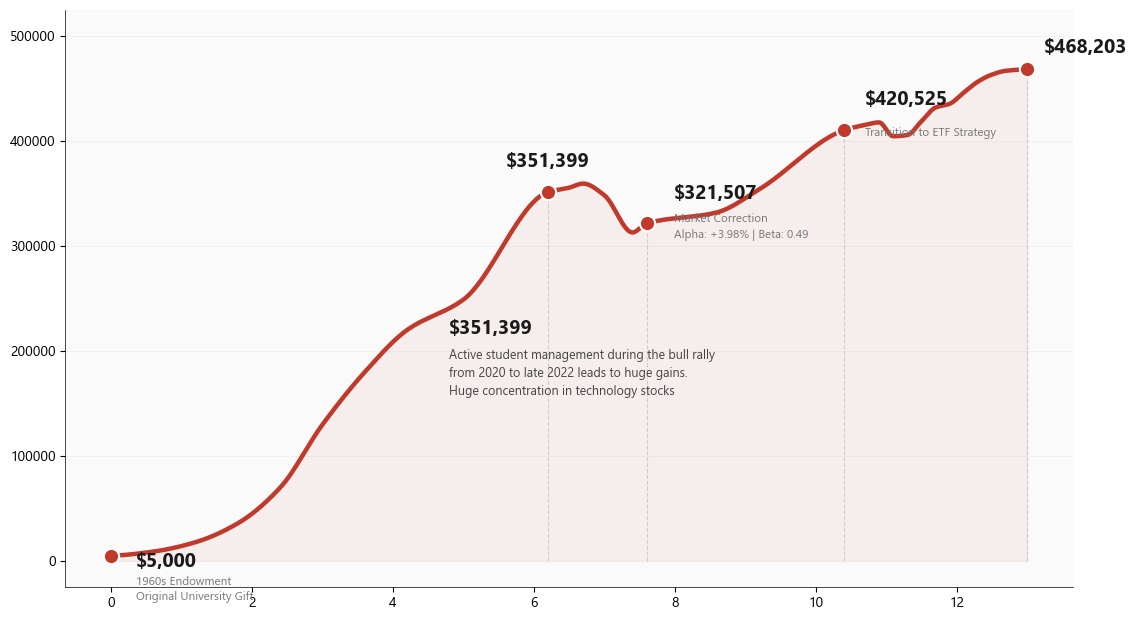

In [4]:
# ============================================================
# BUILD THE CHART
# ============================================================
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
fig.patch.set_facecolor('white')
ax.set_facecolor('#FAFAFA')  # very subtle off-white for chart area

# ---- Smooth red line ----
ax.plot(pos_fine, val_fine,
        color=RED, linewidth=LINE_WIDTH, solid_capstyle='round', zorder=5)

# ---- Filled area under curve ----
ax.fill_between(pos_fine, val_fine, 0,
                color=RED_FILL, alpha=0.06, zorder=2)

# ---- Subtle horizontal grid ----
for yval in [100000, 200000, 300000, 400000, 500000]:
    ax.axhline(y=yval, color=VLIGHT_GRAY, linewidth=0.5, zorder=1)

# ---- Vertical dashed lines at milestones ----
for ms in milestones:
    ax.plot([ms['pos'], ms['pos']], [0, ms['value']],
            color=LIGHT_GRAY, linewidth=0.8, linestyle='--', zorder=3)

# ---- Milestone markers (large red dots) ----
for ms in milestones:
    ax.plot(ms['pos'], ms['value'], 'o',
            color=RED, markersize=MARKER_SIZE, zorder=7,
            markeredgecolor='white', markeredgewidth=1.5)

# ---- Dollar value labels ----
for ms in milestones:
    ax.annotate(
        ms['dollar'],
        xy=(ms['pos'], ms['value']),
        xytext=ms['dollar_offset'],
        textcoords='offset points',
        fontsize=14, fontweight='bold', color=BLACK,
        zorder=10,
    )

# ---- Chart-body description labels (smaller gray text) ----
for ms in milestones:
    if ms['chart_desc']:
        ax.annotate(
            ms['chart_desc'],
            xy=(ms['pos'], ms['value']),
            xytext=ms['desc_offset'],
            textcoords='offset points',
            fontsize=8.5, color=MED_GRAY,
            linespacing=1.4,
            zorder=10,
        )

# ---- Large description text block for the bull-rally period ----
# Positioned in the open space below the 2020-2022 peak line,
# matching the reference's layout between the curve and x-axis.
block_x = 4.8
block_y = 230000

ax.text(
    block_x, block_y,
    "$351,399",
    fontsize=14, color=BLACK, fontweight='bold',
    verticalalignment='top',
    zorder=11,
)
ax.text(
    block_x, block_y - 28000,
    "Active student management during the bull rally\n"
    "from 2020 to late 2022 leads to huge gains.\n"
    "Huge concentration in technology stocks",
    fontsize=9, color=DARK_GRAY, linespacing=1.5,
    verticalalignment='top',
    zorder=10,
)

print('Chart elements plotted.')

---
## Section 5: Axes, Title & Timeline Formatting

### Y-Axis
Dollar amounts formatted as `$100K`, `$200K`, etc. for clean readability.

### X-Axis
Tick marks at milestone positions with labels handled by the bottom timeline
section (not duplicated as x-axis labels).

### Bottom Timeline
A segmented section below the chart with:
- **Date headers** (bold) in evenly-spaced columns
- **Narrative descriptions** below each date
- Thin vertical separators between columns
- Thin horizontal separator line above the timeline

In [5]:
# ============================================================
# AXES FORMATTING
# ============================================================

# Y-axis
ax.set_ylim(-5000, 550000)
ax.set_yticks([100000, 200000, 300000, 400000, 500000])
ax.set_yticklabels(['$100K', '$200K', '$300K', '$400K', '$500K'],
                   fontsize=10, color=MED_GRAY)
ax.tick_params(axis='y', length=0, pad=8)

# X-axis – hide tick labels (dates shown in bottom timeline instead)
ax.set_xlim(-0.8, 13.8)
ax.set_xticks([ms['pos'] for ms in milestones])
ax.set_xticklabels([])  # timeline section below handles date labels
ax.tick_params(axis='x', length=5, color=LIGHT_GRAY, pad=0)

# Spines
ax.spines['bottom'].set_color(LIGHT_GRAY)
ax.spines['left'].set_color(LIGHT_GRAY)

# ============================================================
# LAYOUT  (set FIRST so fig.text positions are correct)
# ============================================================
plt.tight_layout(rect=[0, 0.16, 1, 0.90])

# ============================================================
# TITLE & SUBTITLE  (placed in figure coordinates AFTER layout)
# ============================================================
fig.text(
    0.08, 0.95,
    'PORTFOLIO GROWTH TRAJECTORY',
    fontsize=22, fontweight='bold', color=RED,
    transform=fig.transFigure,
)
fig.text(
    0.08, 0.915,
    'From a $5,000 University Endowment (1960s) to $468,203 (December 2025)  |  +88% Growth Since 2020',
    fontsize=10, color=MED_GRAY,
    transform=fig.transFigure,
)

# ============================================================
# BOTTOM TIMELINE
# ============================================================

# Convert data x-position to figure x-coordinate
def pos_to_fig_x(p):
    """Approximate mapping from data x-position to figure x-coordinate."""
    xlim = ax.get_xlim()
    ax_bbox = ax.get_position()
    frac = (p - xlim[0]) / (xlim[1] - xlim[0])
    return ax_bbox.x0 + frac * ax_bbox.width

# Draw a thin separator line at the bottom of the chart area
ax_bbox = ax.get_position()
separator_y = ax_bbox.y0 - 0.015
fig.add_artist(plt.Line2D(
    [ax_bbox.x0, ax_bbox.x0 + ax_bbox.width],
    [separator_y, separator_y],
    color=LIGHT_GRAY, linewidth=0.8,
    transform=fig.transFigure, zorder=1,
))

# Place timeline descriptions in evenly-spaced columns
timeline_cols = [
    {'fx': 0.11,  'date': '1960s',    'desc': ''},
    {'fx': 0.29,  'date': 'Oct 2021', 'desc': ('Active student management during the bull\n'
                                                 'rally from 2020 to late 2022 leads to huge\n'
                                                 'gains. Huge concentration in technology stocks')},
    {'fx': 0.50,  'date': 'Dec 2023', 'desc': 'Market Correction\nAlpha: +3.98%\n| Beta: 0.49'},
    {'fx': 0.68,  'date': 'Dec 2024', 'desc': 'Transition\nto ETF Strategy'},
    {'fx': 0.84,  'date': 'Dec 2025', 'desc': 'Sharpe: 1.79\nTWRR: 14.12%'},
]

for col in timeline_cols:
    # Date label (bold)
    fig.text(
        col['fx'], separator_y - 0.015,
        col['date'],
        fontsize=9, fontweight='bold', color=DARK_GRAY,
        ha='center', va='top',
        transform=fig.transFigure,
    )
    # Description
    if col['desc']:
        fig.text(
            col['fx'], separator_y - 0.04,
            col['desc'],
            fontsize=7.5, color=MED_GRAY, linespacing=1.3,
            ha='center', va='top',
            transform=fig.transFigure,
        )

# Thin vertical separators between timeline columns
for sep_x in [0.20, 0.39, 0.59, 0.76]:
    fig.add_artist(plt.Line2D(
        [sep_x, sep_x],
        [separator_y - 0.005, separator_y - 0.12],
        color=VLIGHT_GRAY, linewidth=0.6,
        transform=fig.transFigure, zorder=1,
    ))

print('Formatting complete.')
plt.show()

Formatting complete.


<Figure size 640x480 with 0 Axes>

---
## Section 6: Export

Export the chart in two formats:
- **PNG** at 300 DPI — raster format for poster insertion (PowerPoint, Word)
- **PDF** — vector format for maximum quality at any scale

Both are saved to the `output/` directory.

In [6]:
# Re-create the chart for export (plt.show() may have closed it)
# ---- Rebuild everything in one cell for clean export ----

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
fig.patch.set_facecolor('white')
ax.set_facecolor('#FAFAFA')

# Line + fill
ax.plot(pos_fine, val_fine, color=RED, linewidth=LINE_WIDTH,
        solid_capstyle='round', zorder=5)
ax.fill_between(pos_fine, val_fine, 0, color=RED_FILL, alpha=0.06, zorder=2)

# Grid
for yval in [100000, 200000, 300000, 400000, 500000]:
    ax.axhline(y=yval, color=VLIGHT_GRAY, linewidth=0.5, zorder=1)

# Vertical dashed lines + markers + labels
for ms in milestones:
    ax.plot([ms['pos'], ms['pos']], [0, ms['value']],
            color=LIGHT_GRAY, linewidth=0.8, linestyle='--', zorder=3)
    ax.plot(ms['pos'], ms['value'], 'o', color=RED, markersize=MARKER_SIZE,
            zorder=7, markeredgecolor='white', markeredgewidth=1.5)
    ax.annotate(ms['dollar'], xy=(ms['pos'], ms['value']),
                xytext=ms['dollar_offset'], textcoords='offset points',
                fontsize=14, fontweight='bold', color=BLACK, zorder=10)
    if ms['chart_desc']:
        ax.annotate(ms['chart_desc'], xy=(ms['pos'], ms['value']),
                    xytext=ms['desc_offset'], textcoords='offset points',
                    fontsize=8.5, color=MED_GRAY, linespacing=1.4, zorder=10)

# Bull-rally text block
ax.text(4.8, 230000, "$351,399", fontsize=14, color=BLACK,
        fontweight='bold', verticalalignment='top', zorder=11)
ax.text(4.8, 202000,
        "Active student management during the bull rally\n"
        "from 2020 to late 2022 leads to huge gains.\n"
        "Huge concentration in technology stocks",
        fontsize=9, color=DARK_GRAY, linespacing=1.5,
        verticalalignment='top', zorder=10)

# Axes
ax.set_ylim(-5000, 550000)
ax.set_yticks([100000, 200000, 300000, 400000, 500000])
ax.set_yticklabels(['$100K', '$200K', '$300K', '$400K', '$500K'],
                   fontsize=10, color=MED_GRAY)
ax.tick_params(axis='y', length=0, pad=8)
ax.set_xlim(-0.8, 13.8)
ax.set_xticks([ms['pos'] for ms in milestones])
ax.set_xticklabels([])
ax.tick_params(axis='x', length=5, color=LIGHT_GRAY, pad=0)
ax.spines['bottom'].set_color(LIGHT_GRAY)
ax.spines['left'].set_color(LIGHT_GRAY)

# Layout
plt.tight_layout(rect=[0, 0.16, 1, 0.90])

# Title & subtitle
fig.text(0.08, 0.95, 'PORTFOLIO GROWTH TRAJECTORY',
         fontsize=22, fontweight='bold', color=RED)
fig.text(0.08, 0.915,
         'From a $5,000 University Endowment (1960s) to $468,203 (December 2025)  |  +88% Growth Since 2020',
         fontsize=10, color=MED_GRAY)

# Bottom timeline
ax_bbox = ax.get_position()
separator_y = ax_bbox.y0 - 0.015
fig.add_artist(plt.Line2D(
    [ax_bbox.x0, ax_bbox.x0 + ax_bbox.width], [separator_y, separator_y],
    color=LIGHT_GRAY, linewidth=0.8, transform=fig.transFigure))

for col in timeline_cols:
    fig.text(col['fx'], separator_y - 0.015, col['date'],
             fontsize=9, fontweight='bold', color=DARK_GRAY,
             ha='center', va='top', transform=fig.transFigure)
    if col['desc']:
        fig.text(col['fx'], separator_y - 0.04, col['desc'],
                 fontsize=7.5, color=MED_GRAY, linespacing=1.3,
                 ha='center', va='top', transform=fig.transFigure)

for sep_x in [0.20, 0.39, 0.59, 0.76]:
    fig.add_artist(plt.Line2D(
        [sep_x, sep_x], [separator_y - 0.005, separator_y - 0.12],
        color=VLIGHT_GRAY, linewidth=0.6, transform=fig.transFigure))

# ---- Export ----
os.makedirs('output', exist_ok=True)

png_path = os.path.join('output', 'smifc_growth_trajectory_2025.png')
pdf_path = os.path.join('output', 'smifc_growth_trajectory_2025.pdf')

fig.savefig(png_path, dpi=EXPORT_DPI, bbox_inches='tight',
            facecolor='white', pad_inches=0.3)
fig.savefig(pdf_path, bbox_inches='tight',
            facecolor='white', pad_inches=0.3)
plt.close(fig)

print(f'Saved PNG: {png_path}  ({EXPORT_DPI} DPI)')
print(f'Saved PDF: {pdf_path}')
print('\nExport complete.')

Saved PNG: output\smifc_growth_trajectory_2025.png  (300 DPI)
Saved PDF: output\smifc_growth_trajectory_2025.pdf

Export complete.


---
## Section 7: Assumptions & Data Notes

### Assumptions Made
1. **Pre-2021 values are estimated**: No verified data exists for 1962–2020.
   A ~7% compound annual growth rate on the $5,000 endowment is assumed,
   consistent with long-term balanced portfolio returns.
2. **Non-linear x-axis**: The timeline is compressed for the 1960s–2020 period
   and expanded for 2021–2025 to emphasize recent performance detail.
3. **Static milestone labels**: The $420,525 label for Dec 2024 is taken from
   the reference infographic; the verified Month End Market Values show $410,261.

### Verified Data Points
- Oct 2021: $351,399 (Update of Activities report, Oct 23, 2021)
- Dec 2021: $355,545 (End of Semester report, Dec 21, 2021)
- Jan 2022: $359,478 (Beginning of year balance)
- Mar 2022: $348,360 (Q1 2022 report, Mar 28, 2022)
- Jul 2022: $312,948 (June 2023 report, prior period reference)
- Aug 2022: $321,507 (Fall 2022 report, Aug 26, 2022)
- Jun 2023: $332,066 (June 2023 report)
- Dec 2023: $354,075 (Dec 2023 report)
- Dec 2024: $410,261 (Month End Market Values)
- Jan–Dec 2025: Monthly values from Month End Market Values PDF

### How to Customize
To add or modify milestones, edit the `milestones` list in Section 3.
Each entry needs a `pos` (x-position), `value`, `dollar` label,
and offset tuples for text placement. Re-run Section 4 onward to regenerate.

In [7]:
print('Notebook complete. See output/ for exported chart files.')

Notebook complete. See output/ for exported chart files.
